# Fare Prediction Analysis with XGBoost

### 1- Load all necessary data

In [86]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

# Visual styling Parameters
plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "figure.dpi": 120,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
    "axes.grid": False,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "font.size": 10,
})

PRIMARY = "#4575b4"
SECONDARY = "#74add1"
ACCENT = "#d73027"
GRID = "#d9d9d9"

def style_ax(ax, xgrid=False, ygrid=False):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    if xgrid:
        ax.xaxis.grid(True, linestyle="--", linewidth=0.7, alpha=0.6, color=GRID)
    if ygrid:
        ax.yaxis.grid(True, linestyle="--", linewidth=0.7, alpha=0.6, color=GRID)

    ax.set_axisbelow(True)

pd.set_option("display.float_format", "{:,.6f}".format)

def wrap_label(text, width=32):
    return "\n".join(textwrap.wrap(str(text), width=width))

# Load necessary files and data
CWD = Path(".").resolve()

# NOTE: We need this lookup table to map provider and location IDs to actual names e.g. HV0003 -> Uber...
# Download this lookup table in the CWD from https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page using:
# wget https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv

try:
    ZONE_LOOKUP_PATH = CWD / "taxi_zone_lookup.csv"
    zone_lookup = pd.read_csv(ZONE_LOOKUP_PATH)
except:
    print("Could not find taxi_zone_lookup.csv in the current working directory. Attempting to load from URL...")
    zone_lookup = pd.read_csv("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv")

zone_lookup["LocationID"] = zone_lookup["LocationID"].astype(int)

pickup_lookup = zone_lookup.rename(columns={
    "LocationID": "PULocationID",
    "Borough": "pickup_borough",
    "Zone": "pickup_zone",
    "service_zone": "pickup_service_zone",
})

dropoff_lookup = zone_lookup.rename(columns={
    "LocationID": "DOLocationID",
    "Borough": "dropoff_borough",
    "Zone": "dropoff_zone",
    "service_zone": "dropoff_service_zone",
})

feature_importances = pd.read_csv(CWD / "outputs" / "fare_xgb_feature_importances.csv")
predictions = pd.read_csv(CWD / "outputs" / "fare_xgb_test_predictions.csv")
grid_results = pd.read_csv(CWD / "outputs" / "fare_xgb_gridsearch_results.csv")

with open(CWD / "outputs" / "fare_xgb_test_metrics.json", "r") as f:
    test_metrics = json.load(f)

with open(CWD / "outputs" / "fare_xgb_best_params.json", "r") as f:
    best_params = json.load(f)

predictions["pickup_datetime"] = pd.to_datetime(predictions["pickup_datetime"], errors="coerce")
predictions = predictions.merge(pickup_lookup, on="PULocationID", how="left")
predictions = predictions.merge(dropoff_lookup, on="DOLocationID", how="left")

day_name_map = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}
PROVIDER_NAME_MAP = {"HV0002": "Juno", "HV0003": "Uber", "HV0004": "Via", "HV0005": "Lyft"}

predictions["provider_name"] = (
    predictions["hvfhs_license_num"]
    .astype(str)
    .map(PROVIDER_NAME_MAP)
    .fillna(predictions["hvfhs_license_num"].astype(str))
)

summary_df = pd.DataFrame()
summary_df["Metric"] = ["Test MAE", "Test RMSE", "Test R²", "Test rows"]
summary_df["Value"] = [
    test_metrics.get("test_mae"),
    test_metrics.get("test_rmse"),
    test_metrics.get("test_r2"),
    test_metrics.get("n_test_rows"),
]

print("Loaded successfully")

Loaded successfully


### 2- Summary table

In [87]:
rows = []
for key, value in best_params.items():
    rows.append({"Hyperparameter": key, "Best Value": value})
best_hyperparams_table = pd.DataFrame(rows)

print("Summary:")
display(summary_df)

print("\nBest hyperparameters:")
display(best_hyperparams_table)

Summary:


,Metric,Value
0,Test MAE,5.168521
1,Test RMSE,10.408270
2,Test R²,0.837149
3,Test rows,"35,925,320.000000"



Best hyperparameters:


,Hyperparameter,Best Value
0,model__colsample_bytree,0.800000
1,model__learning_rate,0.100000
2,model__max_depth,10.000000
3,model__n_estimators,500.000000
4,model__subsample,0.800000


### 3- Top 15 feature importances

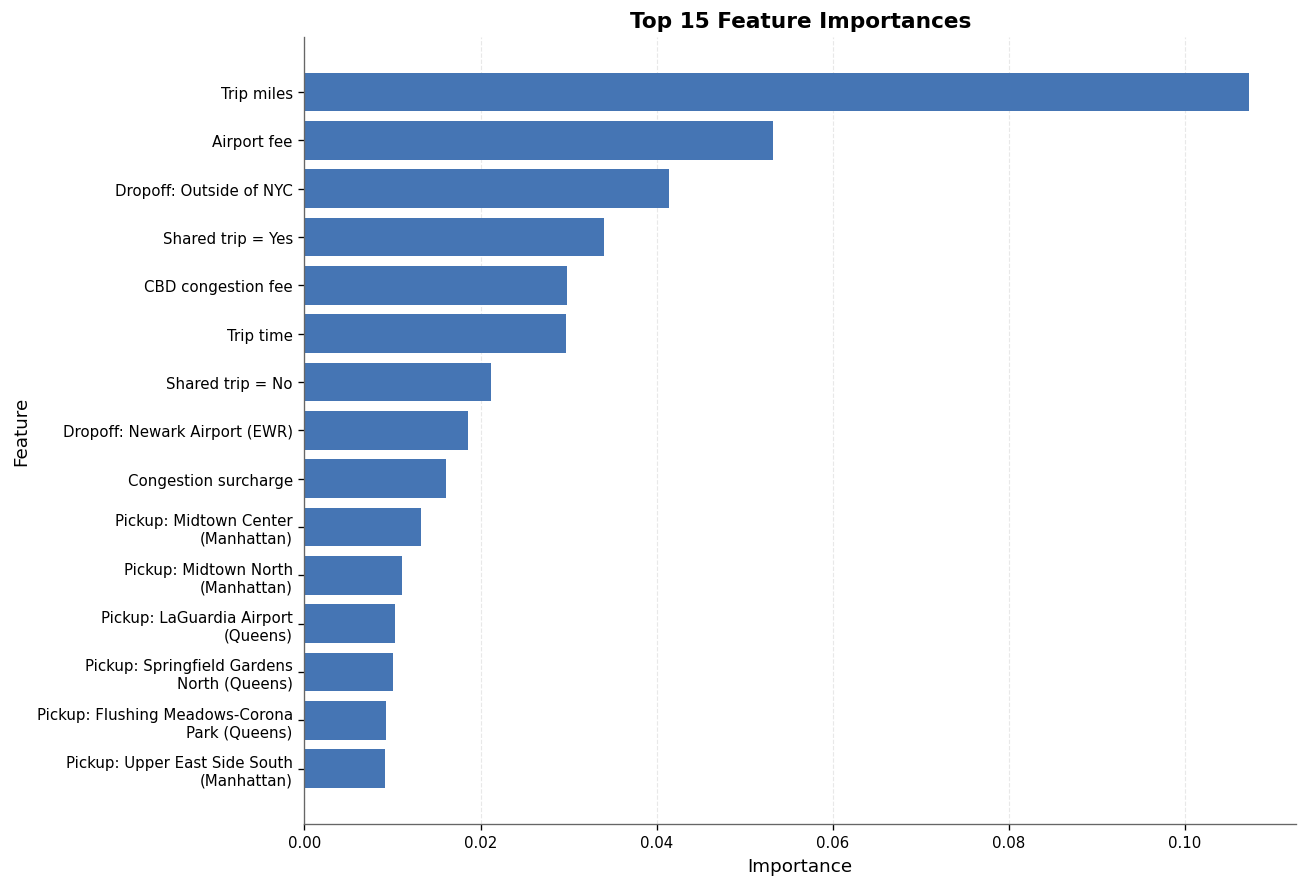

In [88]:
ZONE_NAME_MAP = dict(zip(zone_lookup["LocationID"], zone_lookup["Zone"]))
BOROUGH_NAME_MAP = dict(zip(zone_lookup["LocationID"], zone_lookup["Borough"]))

def clean_feature_name(name):
    name = str(name)

    manual_map = {
        "num__trip_miles": "Trip miles",
        "num__trip_time": "Trip time",
        "num__hour": "Hour of day",
        "num__day_of_week": "Day of week",
        "num__airport_fee": "Airport fee",
        "num__congestion_surcharge": "Congestion surcharge",
        "num__cbd_congestion_fee": "CBD congestion fee",
        "cat__shared_match_flag_Y": "Shared trip = Yes",
        "cat__shared_match_flag_N": "Shared trip = No",
    }

    if name in manual_map:
        return manual_map[name]

    if name.startswith("cat__PULocationID_"):
        location_id = int(name.split("_")[-1])
        zone = str(ZONE_NAME_MAP.get(location_id, f"Pickup zone ID {location_id}"))
        borough = BOROUGH_NAME_MAP.get(location_id)

        if pd.notna(borough) and str(borough).strip() not in {"", "Unknown"}:
            return f"Pickup: {zone} ({borough})"
        return f"Pickup: {zone}"

    if name.startswith("cat__DOLocationID_"):
        location_id = int(name.split("_")[-1])
        zone = str(ZONE_NAME_MAP.get(location_id, f"Dropoff zone ID {location_id}"))
        borough = BOROUGH_NAME_MAP.get(location_id)

        if pd.notna(borough) and str(borough).strip() not in {"", "Unknown"}:
            return f"Dropoff: {zone} ({borough})"
        return f"Dropoff: {zone}"

    if name.startswith("cat__hvfhs_license_num_"):
        provider_code = name.replace("cat__hvfhs_license_num_", "")
        return f"Provider: {PROVIDER_NAME_MAP.get(provider_code, provider_code)}"

    return name

top_n = 15
top_features = feature_importances.head(top_n).copy()
top_features["clean_feature"] = top_features["feature"].apply(clean_feature_name)
top_features["plot_label"] = top_features["clean_feature"].apply(lambda x: wrap_label(x, width=32))
top_features = top_features.sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.barh(top_features["plot_label"], top_features["importance"], color=PRIMARY, edgecolor="none")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
ax.set_title(f"Top {top_n} Feature Importances")
style_ax(ax, xgrid=True)
plt.tight_layout()
plt.show()

### 4- Actual vs predicted scatterplot

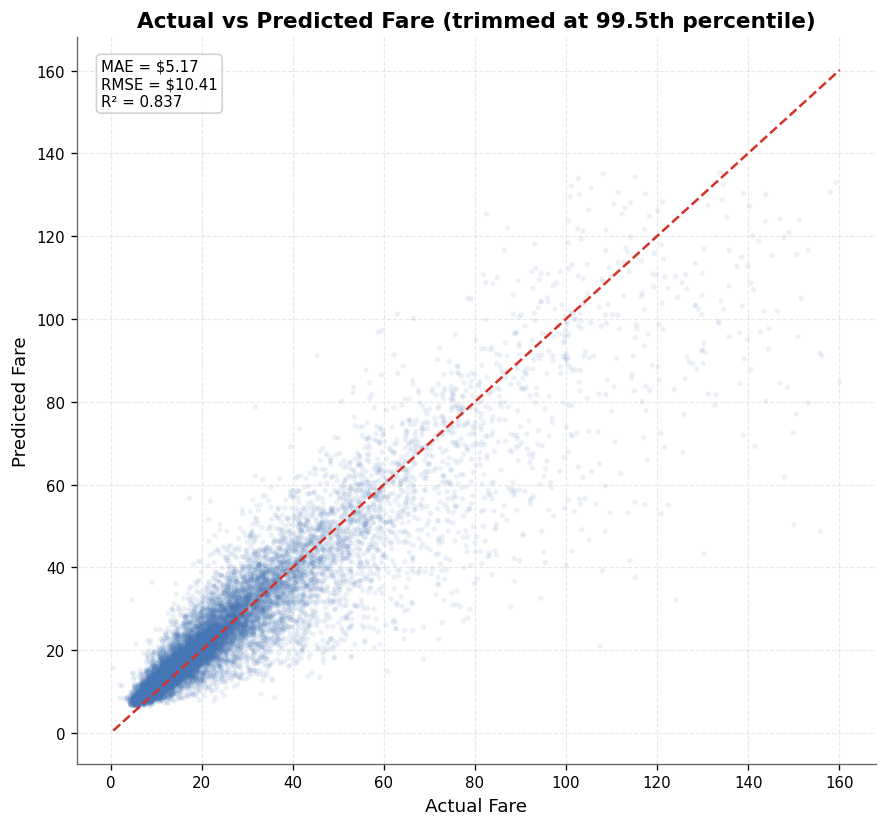

In [89]:
plot_df = predictions[
    (predictions["actual_fare"] <= predictions["actual_fare"].quantile(0.995)) &
    (predictions["predicted_fare"] <= predictions["predicted_fare"].quantile(0.995))
].sample(min(15000, len(predictions)), random_state=42)

xy_min = min(plot_df["actual_fare"].min(), plot_df["predicted_fare"].min())
xy_max = max(plot_df["actual_fare"].max(), plot_df["predicted_fare"].max())

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(
    plot_df["actual_fare"],
    plot_df["predicted_fare"],
    alpha=0.10,
    s=10,
    color=PRIMARY,
    edgecolors="none",
)

ax.plot([xy_min, xy_max], [xy_min, xy_max], color=ACCENT, linewidth=1.5, linestyle="--")
ax.set_xlabel("Actual Fare")
ax.set_ylabel("Predicted Fare")
ax.set_title("Actual vs Predicted Fare (trimmed at 99.5th percentile)")
style_ax(ax, xgrid=True, ygrid=True)

metrics_text = (
    f"MAE = ${test_metrics['test_mae']:.2f}\n"
    f"RMSE = ${test_metrics['test_rmse']:.2f}\n"
    f"R² = {test_metrics['test_r2']:.3f}"
)

ax.text(
    0.03, 0.97, metrics_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#cccccc", alpha=0.9)
)

plt.tight_layout()
plt.show()

### 5- Residual histogram

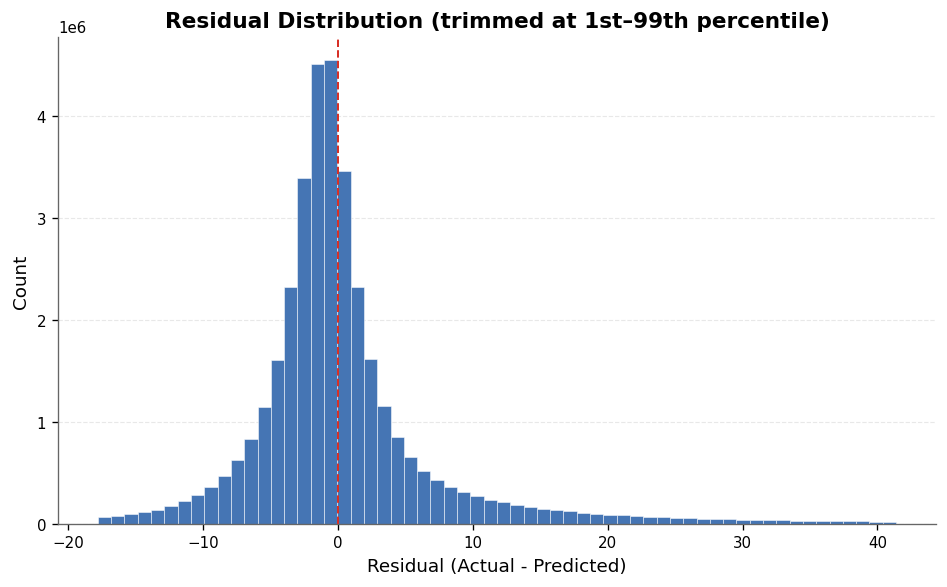

In [90]:
plot_df = predictions.copy()
lower = plot_df["residual"].quantile(0.01)
upper = plot_df["residual"].quantile(0.99)
plot_df = plot_df[(plot_df["residual"] >= lower) & (plot_df["residual"] <= upper)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(plot_df["residual"], bins=60, color=PRIMARY, edgecolor="white", linewidth=0.3)
ax.axvline(0, color=ACCENT, linestyle="--", linewidth=1.2)
ax.set_xlabel("Residual (Actual - Predicted)")
ax.set_ylabel("Count")
ax.set_title("Residual Distribution (trimmed at 1st–99th percentile)")
style_ax(ax, ygrid=True)
plt.tight_layout()
plt.show()

### 6- Residuals vs predicted fare scatterplot

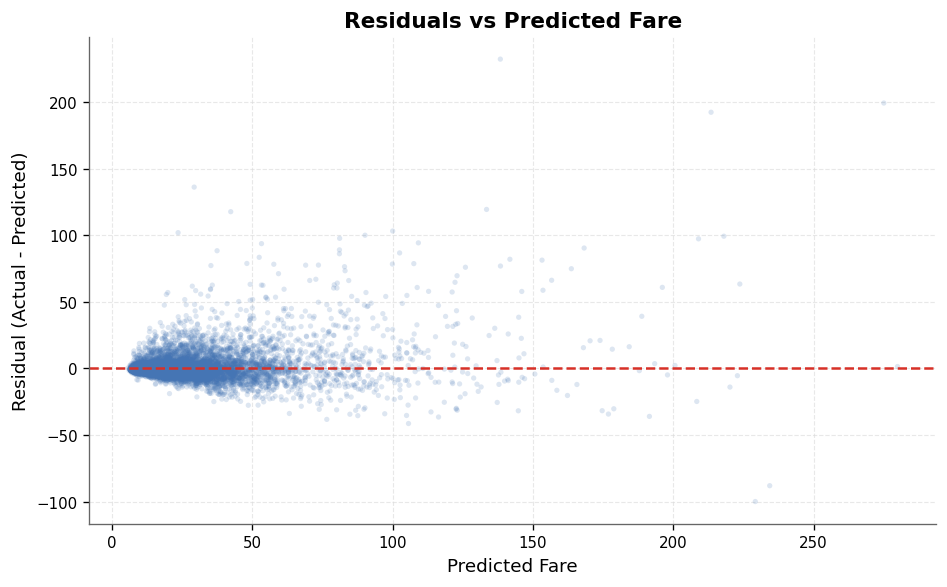

In [91]:
plot_df = predictions.sample(min(10000, len(predictions)), random_state=42)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    plot_df["predicted_fare"],
    plot_df["residual"],
    alpha=0.18,
    s=10,
    color=PRIMARY,
    edgecolors="none",
)
ax.axhline(0, color=ACCENT, linewidth=1.5, linestyle="--")
ax.set_xlabel("Predicted Fare")
ax.set_ylabel("Residual (Actual - Predicted)")
ax.set_title("Residuals vs Predicted Fare")
style_ax(ax, xgrid=True, ygrid=True)
plt.tight_layout()
plt.show()

### 7- MAE by hour of day bar chart

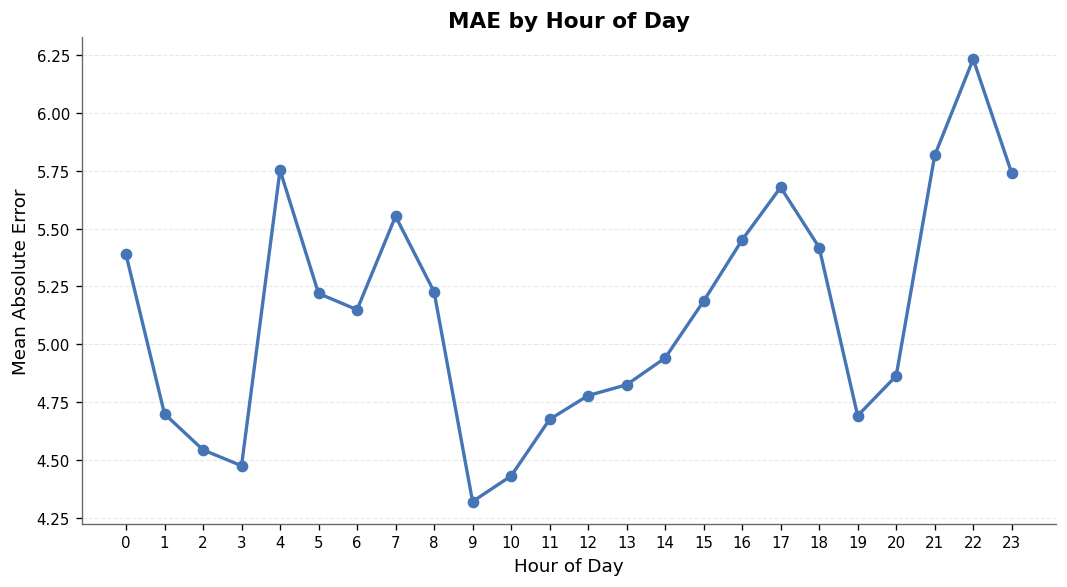

In [92]:
mae_by_hour = (
    predictions.groupby("hour", dropna=False)["abs_error"]
    .mean()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(mae_by_hour.index, mae_by_hour.values, marker="o", color=PRIMARY, linewidth=2) # type: ignore
ax.set_xticks(range(24))
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Mean Absolute Error")
ax.set_title("MAE by Hour of Day")
style_ax(ax, ygrid=True)
plt.tight_layout()
plt.show()

### 8- OPTIONAL TO REPORT: MAE by day of week bar chart

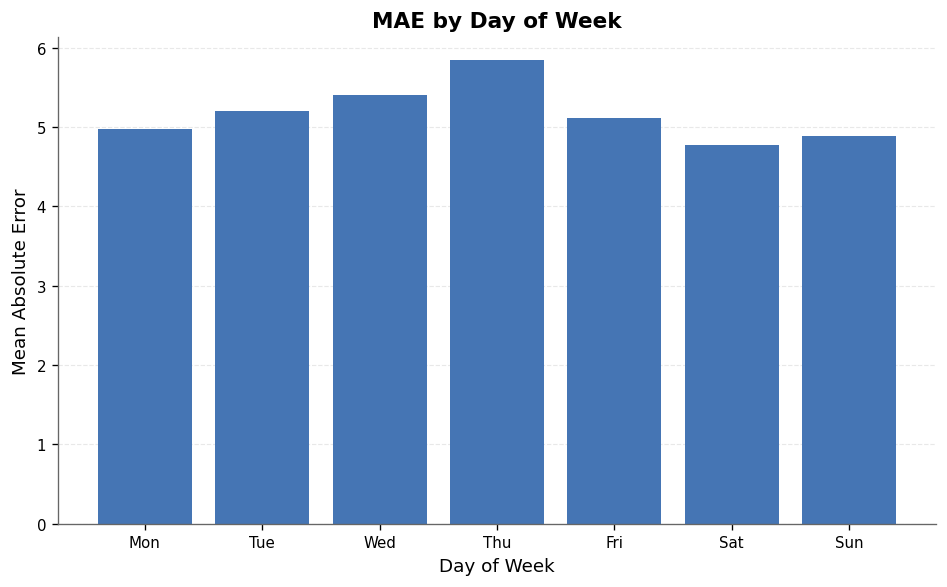

In [93]:
mae_by_day = (
    predictions.groupby("day_of_week", dropna=False)["abs_error"]
    .mean()
    .reset_index()
    .sort_values("day_of_week")
)

mae_by_day["day_name"] = mae_by_day["day_of_week"].map(day_name_map)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(mae_by_day["day_name"], mae_by_day["abs_error"], color=PRIMARY, edgecolor="none")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Mean Absolute Error")
ax.set_title("MAE by Day of Week")
style_ax(ax, ygrid=True)
plt.tight_layout()
plt.show()

### 9- MAE by provider bar chart

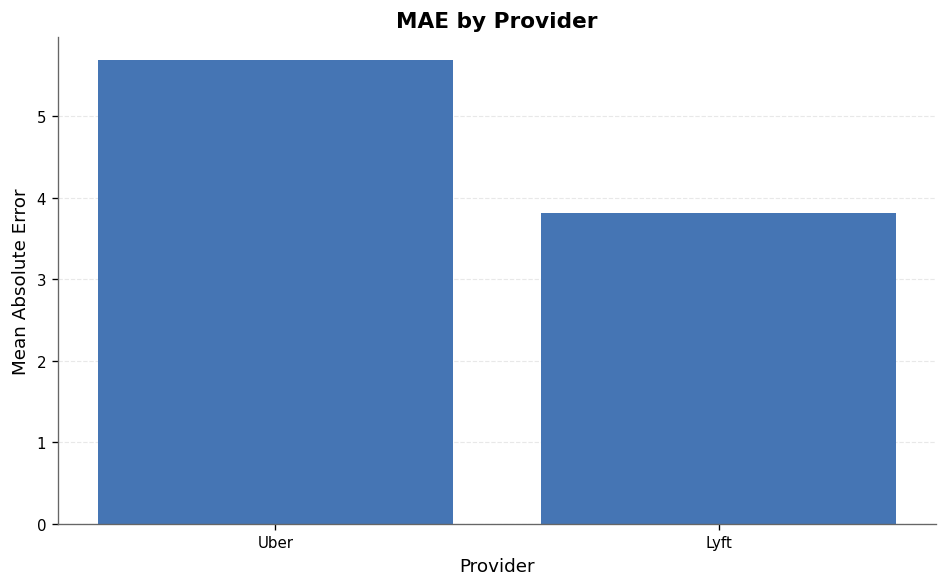

In [94]:
mae_by_provider = (
    predictions.groupby("provider_name", dropna=False)["abs_error"]
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(mae_by_provider.index.astype(str), mae_by_provider.values, color=PRIMARY, edgecolor="none") # type: ignore
ax.set_xlabel("Provider")
ax.set_ylabel("Mean Absolute Error")
ax.set_title("MAE by Provider")
style_ax(ax, ygrid=True)
plt.tight_layout()
plt.show()

### 10- MAE by shared vs non-shared trip

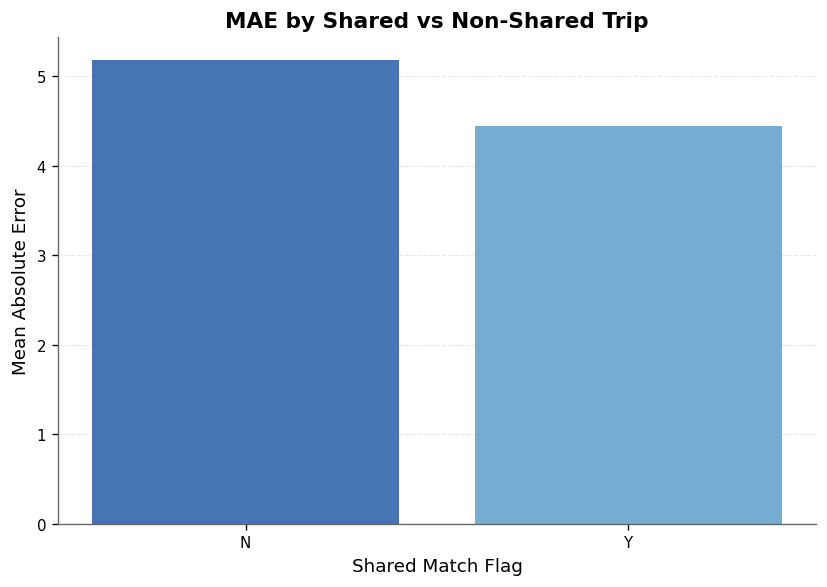

In [95]:
mae_by_shared = (
    predictions.groupby("shared_match_flag", dropna=False)["abs_error"]
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(mae_by_shared.index.astype(str), mae_by_shared.values, color=[PRIMARY, SECONDARY][:len(mae_by_shared)]) # type: ignore
ax.set_xlabel("Shared Match Flag")
ax.set_ylabel("Mean Absolute Error")
ax.set_title("MAE by Shared vs Non-Shared Trip")
style_ax(ax, ygrid=True)
plt.tight_layout()
plt.show()

### 11- Top 10 Worst Pickup Zones by MAE with Borough

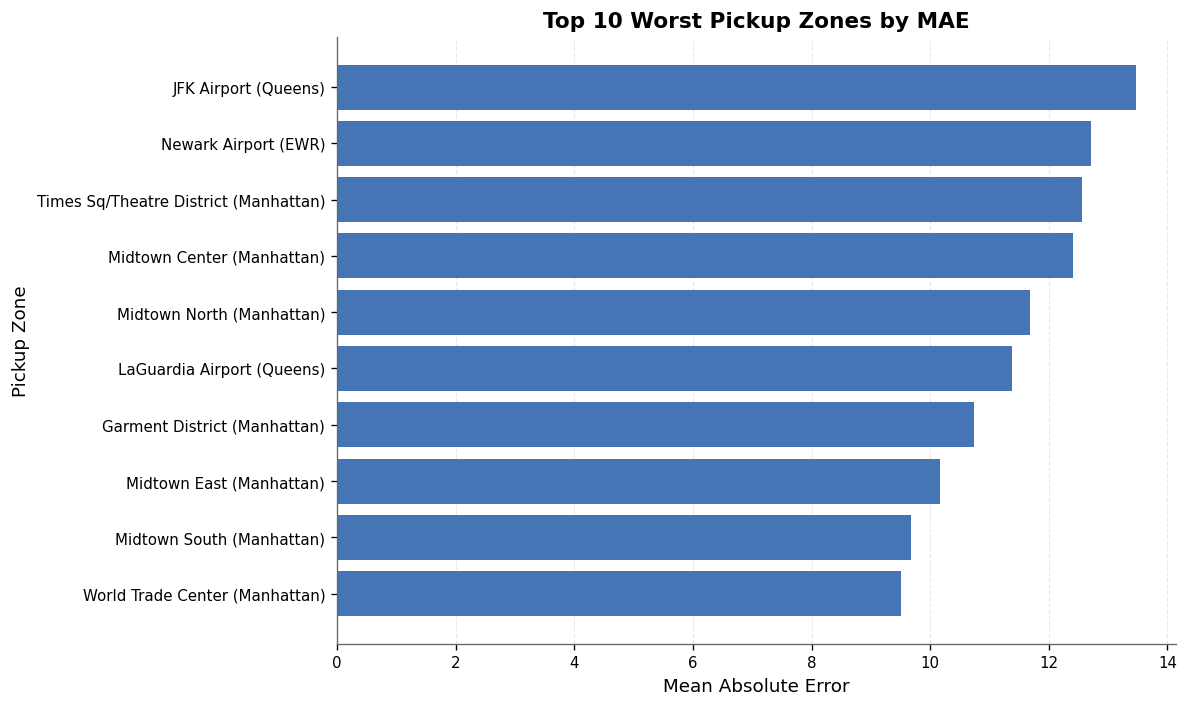

In [96]:
pickup_zone_error = (
    predictions.groupby(["pickup_borough", "pickup_zone"], dropna=False)["abs_error"]
    .mean()
    .reset_index()
)

pickup_zone_error = pickup_zone_error[
    ~pickup_zone_error["pickup_borough"].str.contains("Unknown", case=False, na=False)
    & ~pickup_zone_error["pickup_zone"].str.contains("Unknown", case=False, na=False)
]

pickup_zone_error["label"] = (
    pickup_zone_error["pickup_zone"].astype(str)
    + " ("
    + pickup_zone_error["pickup_borough"].astype(str)
    + ")"
)

worst_pickup_zones = (
    pickup_zone_error.sort_values("abs_error", ascending=False)
    .head(10)
    .sort_values("abs_error", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(worst_pickup_zones["label"], worst_pickup_zones["abs_error"], color=PRIMARY, edgecolor="none")
ax.set_xlabel("Mean Absolute Error")
ax.set_ylabel("Pickup Zone")
ax.set_title("Top 10 Worst Pickup Zones by MAE")
style_ax(ax, xgrid=True)
plt.tight_layout()
plt.show()

### 12- Top 10 Worst Dropoff Zones by MAE with Borough

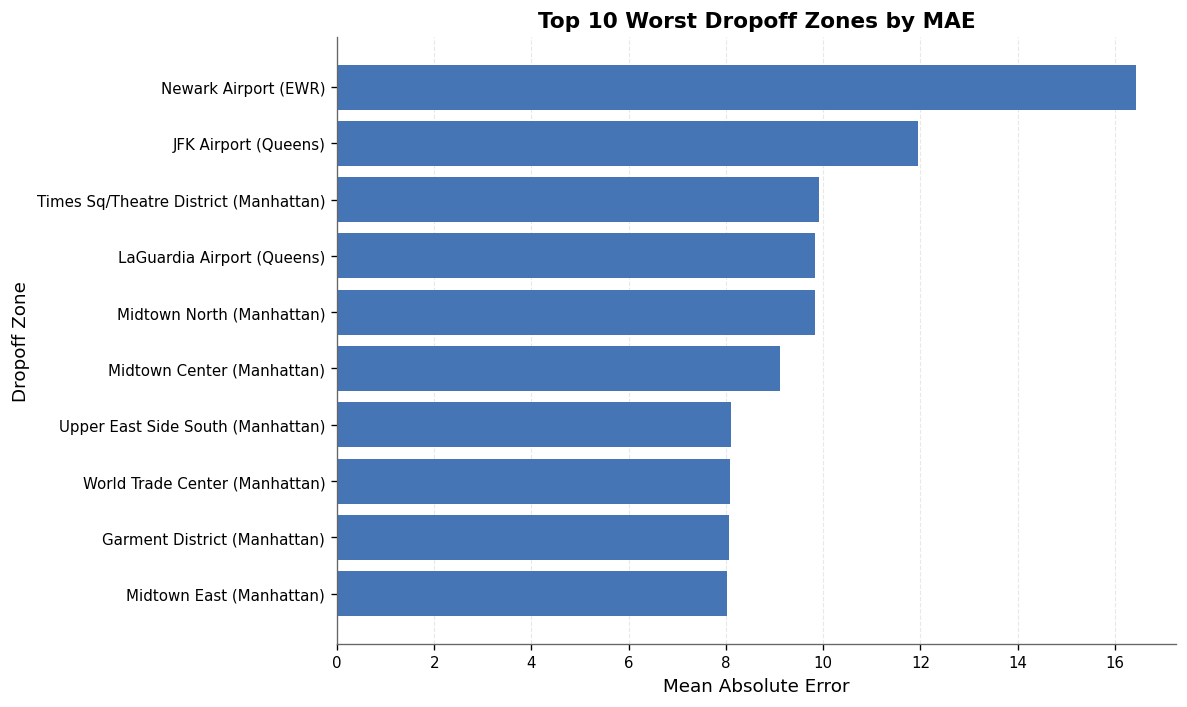

In [97]:
dropoff_zone_error = (
    predictions.assign(
        dropoff_borough_label=predictions["dropoff_borough"].fillna("Unknown").astype(str),
        dropoff_zone_label=predictions["dropoff_zone"].fillna("Unknown").astype(str),
    )
    .groupby(["dropoff_borough_label", "dropoff_zone_label"], dropna=False)["abs_error"]
    .mean()
    .reset_index()
)

dropoff_zone_error = dropoff_zone_error[
    ~dropoff_zone_error["dropoff_borough_label"].str.contains("Unknown", case=False, na=False)
    & ~dropoff_zone_error["dropoff_zone_label"].str.contains("Unknown", case=False, na=False)
]


dropoff_zone_error["label"] = (
    dropoff_zone_error["dropoff_zone_label"]
    + " ("
    + dropoff_zone_error["dropoff_borough_label"]
    + ")"
)

worst_dropoff_zones = (
    dropoff_zone_error.sort_values("abs_error", ascending=False)
    .head(10)
    .sort_values("abs_error", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(worst_dropoff_zones["label"], worst_dropoff_zones["abs_error"], color=PRIMARY, edgecolor="none")
ax.set_xlabel("Mean Absolute Error")
ax.set_ylabel("Dropoff Zone")
ax.set_title("Top 10 Worst Dropoff Zones by MAE")
style_ax(ax, xgrid=True)
plt.tight_layout()
plt.show()